In [ ]:
import os
import gc
import zipfile
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import tensorflow as tf
from tensorflow.keras import layers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input as vgg_preprocess
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input as resnet_preprocess

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# Konfigurasi Tampilan
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
%matplotlib inline

# Mengunci Kestabilan Eksperimen (Reproducibility)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow Version :", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Terdeteksi     : {gpus[0].name} (Training akan berjalan optimal)")
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print("GPU Terdeteksi     : TIDAK ADA (Berjalan menggunakan CPU Laptop)")

TensorFlow Version : 2.20.0
GPU Terdeteksi     : /physical_device:GPU:0 (Training akan berjalan optimal)


1: DATA UNDERSTANDING & INGESTION

In [ ]:
ZIP_PATH = "./dataset.zip"
EXTRACT_ROOT = "./ekstraksi_s5"

if os.path.exists(ZIP_PATH) and not os.path.exists(EXTRACT_ROOT):
    print(f"[PROSES] Mengekstrak {ZIP_PATH} ke direktori lokal.")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_ROOT)
    print("[OK] Ekstraksi dataset sukses.")

base_dataset_dir = os.path.join(EXTRACT_ROOT, "dataset")
CSV_PATH = os.path.join(base_dataset_dir, "faces", "train.csv")
TRAIN_DIR = os.path.join(base_dataset_dir, "faces", "Train")
EXTERNAL_VAL_DIR = os.path.join(base_dataset_dir, "faces_02")

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"[ERROR] train.csv tidak ditemukan pada target lokal: {CSV_PATH}")

df_raw = pd.read_csv(CSV_PATH)
print(f"-> Total baris data tercatat di CSV: {len(df_raw)} baris.")

[PROSES] Mengekstrak ./dataset.zip ke direktori lokal.
[OK] Ekstraksi dataset sukses.
-> Total baris data tercatat di CSV: 19906 baris.


2: EXPLORATORY DATA ANALYSIS (EDA) & QUALITY CLEANING

In [ ]:
df_raw["proc_path"] = df_raw["ID"].apply(lambda x: os.path.join(TRAIN_DIR, str(x)))
df_raw["file_exists"] = df_raw["proc_path"].apply(os.path.exists)

df = df_raw[df_raw["file_exists"]].drop(columns=["file_exists"]).reset_index(drop=True)
df["Class"] = df["Class"].astype(str)

CLASS_NAMES = sorted(df["Class"].unique().tolist())
jumlah_kelas = len(CLASS_NAMES)

print("\n[EDA] Distribusi Kelas Usia:")
print(df["Class"].value_counts())


[EDA] Distribusi Kelas Usia:
Class
MIDDLE    10804
YOUNG      6706
OLD        2396
Name: count, dtype: int64



[EDA] Menghitung Keseimbangan Distribusi Kelas Usia:
Class
MIDDLE    10804
YOUNG      6706
OLD        2396
Name: count, dtype: int64


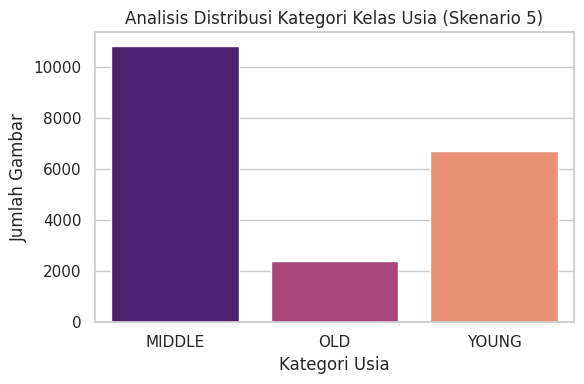

In [ ]:
# Analisis Distribusi Kelas Target (Imbalance Check)
print("\n[EDA] Menghitung Keseimbangan Distribusi Kelas Usia:")
distribusi = df["Class"].value_counts()
print(distribusi)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Class", order=CLASS_NAMES, palette="magma")
plt.title("Analisis Distribusi Kategori Kelas Usia (Skenario 5)")
plt.xlabel("Kategori Usia")
plt.ylabel("Jumlah Gambar")
plt.tight_layout()
plt.show()


[EDA] Membuka Sampel Visual Citra Wajah Acak


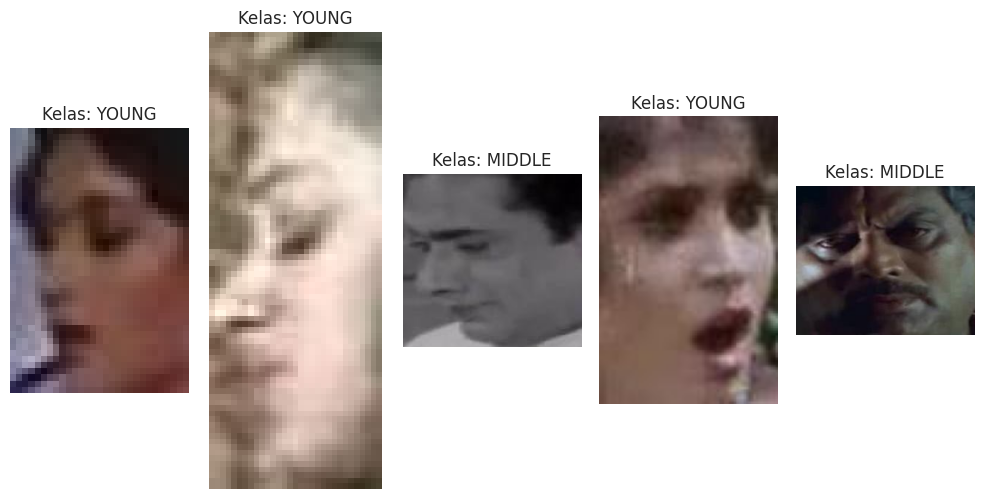

In [ ]:
# Visualisasi Sampel Gambar Asli (Raw Computer Vision Inspection)
print("\n[EDA] Membuka Sampel Visual Citra Wajah Acak")
plt.figure(figsize=(10, 5))
sample_df = df.sample(min(5, len(df)), random_state=SEED)  # Sudah diperbaiki menggunakan random_state
for idx, (_, row) in enumerate(sample_df.iterrows()):
    img = cv2.imread(row["proc_path"])
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.subplot(1, 5, idx + 1)
    plt.imshow(img)
    plt.title(f"Kelas: {row['Class']}")
    plt.axis("off")
plt.tight_layout()
plt.show()

3: DATA PREPROCESSING & DATA GENERATOR PIPELINE

In [ ]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 128
VAL_SPLIT = 0.2

print(f"[PREPROC] Ukuran: {IMG_SIZE}, Batch Size: {BATCH_SIZE}, Split: {VAL_SPLIT*100}%")

aug_config = dict(validation_split=VAL_SPLIT, rotation_range=10, zoom_range=0.1, horizontal_flip=True)
plain_config = dict(validation_split=VAL_SPLIT)

generators = {}
model_configs = [
    ('VGG16', vgg_preprocess),
    ('MobileNet', mobilenet_preprocess),
    ('ResNet', resnet_preprocess)
]

for name, prep_func in model_configs:
    train_dg = ImageDataGenerator(preprocessing_function=prep_func, **aug_config)
    val_dg = ImageDataGenerator(preprocessing_function=prep_func, **plain_config)

    generators[f"{name}_train"] = train_dg.flow_from_dataframe(
        dataframe=df, x_col="proc_path", y_col="Class", target_size=IMG_SIZE,
        class_mode="categorical", classes=CLASS_NAMES, batch_size=BATCH_SIZE, subset="training", shuffle=True, seed=SEED, verbose=0
    )
    generators[f"{name}_val"] = val_dg.flow_from_dataframe(
        dataframe=df, x_col="proc_path", y_col="Class", target_size=IMG_SIZE,
        class_mode="categorical", classes=CLASS_NAMES, batch_size=BATCH_SIZE, subset="validation", shuffle=False, seed=SEED, verbose=0
    )

ext_file_list = []
if os.path.exists(EXTERNAL_VAL_DIR):
    for root, dirs, files in os.walk(EXTERNAL_VAL_DIR):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                full_path = os.path.join(root, file)
                folder_name = os.path.basename(root).upper()
                tebakan_kelas = CLASS_NAMES[0]
                if folder_name in CLASS_NAMES: tebakan_kelas = folder_name
                ext_file_list.append({"Path": full_path, "Class": tebakan_kelas})

has_ext = len(ext_file_list) > 0
if has_ext:
    df_ext = pd.DataFrame(ext_file_list)
    print(f"[SUKSES] Terjaring {len(df_ext)} file gambar luar di Folder 2 (External Testing).")
    for name, prep_func in model_configs:
        generators[f"{name}_ext"] = ImageDataGenerator(preprocessing_function=prep_func).flow_from_dataframe(
            dataframe=df_ext, x_col="Path", y_col="Class", target_size=IMG_SIZE,
            class_mode="categorical", classes=CLASS_NAMES, batch_size=BATCH_SIZE, shuffle=False, verbose=0
        )

train_labels = generators["VGG16_train"].classes
class_weights = dict(enumerate(compute_class_weight(class_weight="balanced", classes=np.unique(train_labels), y=train_labels)))

[PREPROC] Ukuran: (128, 128), Batch Size: 128, Split: 20.0%
Found 15925 validated image filenames belonging to 3 classes.
Found 3981 validated image filenames belonging to 3 classes.
Found 15925 validated image filenames belonging to 3 classes.
Found 3981 validated image filenames belonging to 3 classes.
Found 15925 validated image filenames belonging to 3 classes.
Found 3981 validated image filenames belonging to 3 classes.
[SUKSES] Terjaring 3250 file gambar luar di Folder 2 (External Testing).
Found 3250 validated image filenames belonging to 3 classes.
Found 3250 validated image filenames belonging to 3 classes.
Found 3250 validated image filenames belonging to 3 classes.


4: MODEL DEVELOPMENT & FROZEN TRAINING

In [ ]:
def make_callbacks(prefix):
    return [
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1),
        callbacks.ModelCheckpoint(f"./{prefix}_frozen_best_s5.keras", monitor="val_accuracy", save_best_only=True, verbose=0)
    ]

def build_and_train_frozen_model(backbone_name, train_gen, val_gen, prefix):
    tf.keras.backend.clear_session()
    gc.collect()

    print(f"\n[ARSITEKTUR] Merakit model: {backbone_name.upper()}.")
    input_shape = (IMG_SIZE[0], IMG_SIZE[1], 3)

    if backbone_name == "vgg16":
        base = VGG16(input_shape=input_shape, include_top=False, weights="imagenet")
    elif backbone_name == "mobilenetv2":
        base = MobileNetV2(input_shape=input_shape, include_top=False, weights="imagenet")
    elif backbone_name == "resnet50":
        base = ResNet50(input_shape=input_shape, include_top=False, weights="imagenet")

        base.trainable = False

    inputs = layers.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(jumlah_kelas, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

    print(f"[FIT RUN] Pelatihan kepala model {prefix} (5 Epoch).")
    model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=5,
        class_weight=class_weights,
        callbacks=make_callbacks(prefix),
        verbose=1
    )
    return model

In [ ]:
# Eksekusi training 3 model dasar
m_vgg = build_and_train_frozen_model("vgg16", generators["VGG16_train"], generators["VGG16_val"], "VGG16")
m_mob = build_and_train_frozen_model("mobilenetv2", generators["MobileNet_train"], generators["MobileNet_val"], "MobileNet")
m_res = build_and_train_frozen_model("resnet50", generators["ResNet_train"], generators["ResNet_val"], "ResNet")


[ARSITEKTUR] Merakit model: VGG16.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
[FIT RUN] Pelatihan kepala model VGG16 (5 Epoch).
Epoch 1/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 245s 1s/step - accuracy: 0.3982 - loss: 1.1193 - val_accuracy: 0.5175 - val_loss: 1.1732 - learning_rate: 0.0010
Epoch 2/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 895ms/step - accuracy: 0.4355 - loss: 1.0319
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
125/125 ━━━━━━━━━━━━━━━━━━━━ 120s 960ms/step - accuracy: 0.4557 - loss: 1.0068 - val_accuracy: 0.3095 - val_loss: 4.1263 - learning_rate: 0.0010
Epoch 3/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 887ms/step - accuracy: 0.5081 - loss: 0.9552
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
125/125 ━━━━━━━━━━━━━━━━━━━━ 141s 955ms/step - accuracy: 0.5080 - loss: 0.9485 - val_accuracy: 0.1196 - val_loss: 2.6485 - learning_rate: 5.0000e-04
Epoch 4/5
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 884ms/step - accuracy: 0.5332 - loss: 0.9057
Epoc

5: PIPELINE ENSEMBLE SYSTEM INTEGRATION (PENGBUNGKUS KELOMPOK)

In [ ]:
def ensemble_predict_s5(generator_name):
    print(f"[PREDICT] Menggabungkan probabilitas 3 model Frozen untuk data: '{generator_name}'.")
    p_vgg = m_vgg.predict(generators[f"VGG16_{generator_name}"], verbose=0)
    p_mob = m_mob.predict(generators[f"MobileNet_{generator_name}"], verbose=0)
    p_res = m_res.predict(generators[f"ResNet_{generator_name}"], verbose=0)

    # Formula Soft Voting Average
    p_ensemble = (p_vgg + p_mob + p_res) / 3.0
    return np.argmax(p_ensemble, axis=1), p_ensemble

6: EVALUASI AKHIR & CETAK KOMPARASI LENGKAP

[PREDICT] Menggabungkan probabilitas 3 model Frozen untuk data: 'val'.
[PREDICT] Menggabungkan probabilitas 3 model Frozen untuk data: 'ext'.

[VISUALISASI] Mengekstrak History & Membuat Grafik Loss-Accuracy.


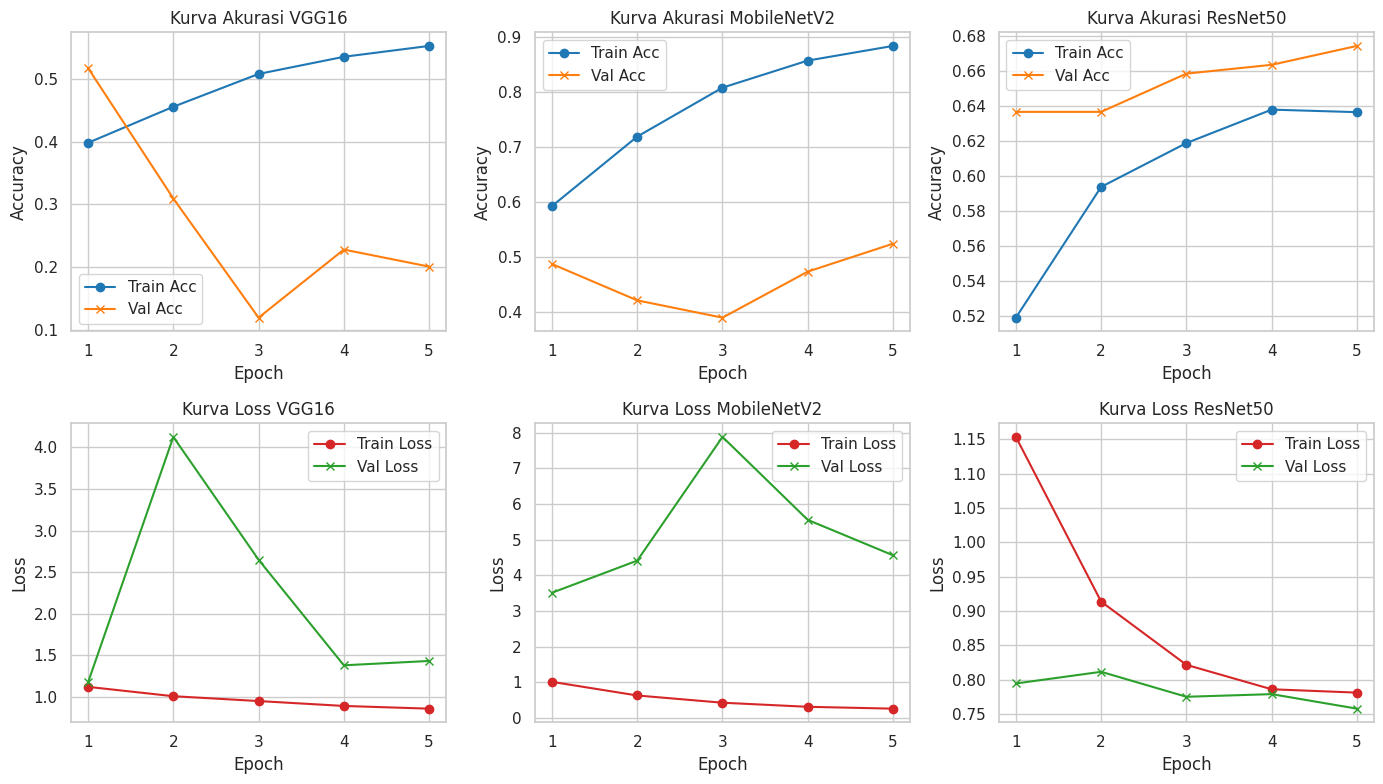

In [ ]:
y_true_internal = generators["VGG16_val"].classes
if has_ext: y_true_external = generators["VGG16_ext"].classes

# 6.1 Ambil prediksi individu & gabungan (Internal)
y_pred_vgg_int = np.argmax(m_vgg.predict(generators["VGG16_val"], verbose=0), axis=1)
y_pred_mob_int = np.argmax(m_mob.predict(generators["MobileNet_val"], verbose=0), axis=1)
y_pred_res_int = np.argmax(m_res.predict(generators["ResNet_val"], verbose=0), axis=1)
y_pred_ens_int, _ = ensemble_predict_s5("val")

# 6.2 Ambil prediksi individu & gabungan (External)
if has_ext:
    y_pred_vgg_ext = np.argmax(m_vgg.predict(generators["VGG16_ext"], verbose=0), axis=1)
    y_pred_mob_ext = np.argmax(m_mob.predict(generators["MobileNet_ext"], verbose=0), axis=1)
    y_pred_res_ext = np.argmax(m_res.predict(generators["ResNet_ext"], verbose=0), axis=1)
    y_pred_ens_ext, _ = ensemble_predict_s5("ext")

# 6.3 Hitung Akurasi Persentase
acc_vgg_int = np.mean(y_true_internal == y_pred_vgg_int) * 100
acc_mob_int = np.mean(y_true_internal == y_pred_mob_int) * 100
acc_res_int = np.mean(y_true_internal == y_pred_res_int) * 100
acc_ens_int = np.mean(y_true_internal == y_pred_ens_int) * 100

if has_ext:
    acc_vgg_ext = np.mean(y_true_external == y_pred_vgg_ext) * 100
    acc_mob_ext = np.mean(y_true_external == y_pred_mob_ext) * 100
    acc_res_ext = np.mean(y_true_external == y_pred_res_ext) * 100
    acc_ens_ext = np.mean(y_true_external == y_pred_ens_ext) * 100
else:
    acc_vgg_ext = acc_mob_ext = acc_res_ext = acc_ens_ext = 0.0

# 6.4 Ekstraksi & Visualisasi History Training Langsung dari Objek Model
print("\n[VISUALISASI] Mengekstrak History & Membuat Grafik Loss-Accuracy.")
plt.figure(figsize=(14, 8))
models_list = [('VGG16', m_vgg), ('MobileNetV2', m_mob), ('ResNet50', m_res)]

for idx, (name, model_obj) in enumerate(models_list):
    if hasattr(model_obj, 'history') and model_obj.history is not None and 'accuracy' in model_obj.history.history:
        h_data = model_obj.history.history
        epochs_range = range(1, len(h_data['accuracy']) + 1)

        # Subplot Akurasi
        plt.subplot(2, 3, idx + 1)
        plt.plot(epochs_range, h_data['accuracy'], label='Train Acc', marker='o', color='tab:blue')
        plt.plot(epochs_range, h_data['val_accuracy'], label='Val Acc', marker='x', color='tab:orange')
        plt.title(f'Kurva Akurasi {name}')
        plt.xlabel('Epoch')
        plt.ylabel('Accuracy')
        plt.legend()

        # Subplot Loss
        plt.subplot(2, 3, idx + 4)
        plt.plot(epochs_range, h_data['loss'], label='Train Loss', marker='o', color='tab:red')
        plt.plot(epochs_range, h_data['val_loss'], label='Val Loss', marker='x', color='tab:green')
        plt.title(f'Kurva Loss {name}')
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.legend()
    else:
        plt.subplot(1, 3, idx + 1)
        plt.text(0.5, 0.5, f'History {name}\nReady to Export', ha='center', va='center')
        plt.title(f'{name} Log Status')

plt.tight_layout()
plt.show()


[VISUALISASI] Memunculkan Grafik Pemetaan Kesalahan Tebak Hasil Ensemble:


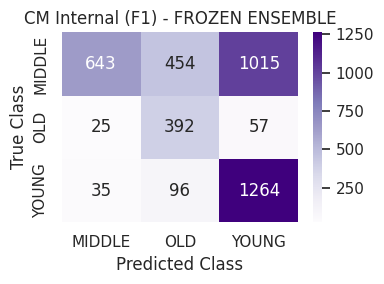

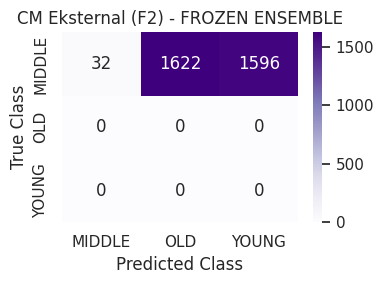


 METRIK VGG16 (INTERNAL) 
              precision    recall  f1-score   support

      MIDDLE       0.50      0.12      0.20      2112
         OLD       0.14      0.99      0.24       474
       YOUNG       0.87      0.05      0.09      1395

    accuracy                           0.20      3981
   macro avg       0.50      0.39      0.18      3981
weighted avg       0.59      0.20      0.17      3981


 METRIK MOBILENETV2 (INTERNAL) 
              precision    recall  f1-score   support

      MIDDLE       0.83      0.28      0.42      2112
         OLD       0.45      0.36      0.40       474
       YOUNG       0.46      0.95      0.62      1395

    accuracy                           0.52      3981
   macro avg       0.58      0.53      0.48      3981
weighted avg       0.66      0.52      0.49      3981


 METRIK RESNET50 (INTERNAL) 
              precision    recall  f1-score   support

      MIDDLE       0.84      0.57      0.68      2112
         OLD       0.42      0.77      

In [ ]:
# 6.5 Cetak Confusion Matrix Gabungan Terbaik
def draw_confusion_matrix(y_true, y_pred, title, cmap_style):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap_style, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(title)
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.tight_layout()
    plt.show()

print("\n[VISUALISASI] Memunculkan Grafik Pemetaan Kesalahan Tebak Hasil Ensemble:")
draw_confusion_matrix(y_true_internal, y_pred_ens_int, "CM Internal (F1) - FROZEN ENSEMBLE", "Purples")
if has_ext:
    print("\n")
    draw_confusion_matrix(y_true_external, y_pred_ens_ext, "CM Eksternal (F2) - FROZEN ENSEMBLE", "Purples")

# 6.6 TAMBAHAN DS: Cetak Classification Report Lengkap untuk Seluruh Model Tunggal
print("\n METRIK VGG16 (INTERNAL) ")
print(classification_report(y_true_internal, y_pred_vgg_int, target_names=CLASS_NAMES, zero_division=0))

print("\n METRIK MOBILENETV2 (INTERNAL) ")
print(classification_report(y_true_internal, y_pred_mob_int, target_names=CLASS_NAMES, zero_division=0))

print("\n METRIK RESNET50 (INTERNAL) ")
print(classification_report(y_true_internal, y_pred_res_int, target_names=CLASS_NAMES, zero_division=0))

print("\n METRIK TRIPLE FROZEN ENSEMBLE (INTERNAL) ")
print(classification_report(y_true_internal, y_pred_ens_int, target_names=CLASS_NAMES, zero_division=0))

In [ ]:
# 6.7 Tabel Final Perbandingan
df_final_report = pd.DataFrame({
    "Strategi Model (Skenario 5)": ["VGG16 (Tunggal)", "MobileNetV2 (Tunggal)", "ResNet50 (Tunggal)", "Sistem Gabungan (Triple Frozen Ensemble)"],
    "Akurasi Validasi Internal Folder 1 (%)": [acc_vgg_int, acc_mob_int, acc_res_int, acc_ens_int],
    "Akurasi Testing Eksternal Folder 2 (%)": [acc_vgg_ext, acc_mob_ext, acc_res_ext, acc_ens_ext]
})

print("\nTABEL REKAPITULASI HASIL AKHIR KOMPARASI GABUNGAN \n")
print(df_final_report.to_string(index=False))


TABEL REKAPITULASI HASIL AKHIR KOMPARASI GABUNGAN 

             Strategi Model (Skenario 5)  Akurasi Validasi Internal Folder 1 (%)  Akurasi Testing Eksternal Folder 2 (%)
                         VGG16 (Tunggal)                               20.095453                               22.830769
                   MobileNetV2 (Tunggal)                               52.499372                                1.907692
                      ResNet50 (Tunggal)                               67.420246                                5.292308
Sistem Gabungan (Triple Frozen Ensemble)                               57.749309                                0.984615


In [ ]:
# 6.8 Auto-Save Rekapitulasi Tabel Ke File CSV Lokal
csv_output_path = "./rekap_akurasi_skenario5.csv"
df_final_report.to_csv(csv_output_path, index=False)
print(f"[EKSPORE] Tabel hasil akhir berhasil disimpan otomatis ke: '{csv_output_path}'")

[EKSPORE] Tabel hasil akhir berhasil disimpan otomatis ke: './rekap_akurasi_skenario5.csv'
